# Dự báo doanh số bán hàng theo mùa bằng Random Forest
### EDA + Tiền xử lý dữ liệu + So sánh 3 mô hình (Linear Regression, Decision Tree, Random Forest)

Notebook gồm 6 phần:
1. Tải dữ liệu
2. EDA trước tiền xử lý (bảng & biểu đồ khảo sát dữ liệu gốc)
3. Tiền xử lý dữ liệu
4. EDA sau tiền xử lý (biểu đồ phân phối, tương quan, theo mùa...)
5. Huấn luyện 3 mô hình
6. Trực quan hóa & so sánh kết quả mô hình


In [10]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.ensemble import RandomForestRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import warnings
warnings.filterwarnings('ignore')

np.random.seed(42)
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['font.size'] = 11


## Phần 1: Tải dữ liệu


In [12]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [13]:
import os
print(os.path.exists("/content/drive/MyDrive"))

True


In [14]:
import os

print(os.listdir("/content/drive/MyDrive"))

['Bảo hiểm xe', 'Colab Notebooks', 'NCKH.jpg', 'Vocab.gsheet', 'KDTM', 'THUYETMINH(2) (1).docx', 'THUYETMINH(2).docx', 'Học máy và TTNT', 'Báo cáo Khai phá T4 nhóm 5', 'data_da_xu_ly.csv', 'Thực hành Khai phá T4', 'Hệ thống phân tích cảm xúc đánh giá khách hàng cho sản phẩm mỹ phẩm Cocoon.gdoc', 'ST3_TheYobae_Cocoon_Baocaocuoiky.zip']


In [15]:
#from google.colab import files
#uploaded = files.upload()   # chọn file data_da_xu_ly.xlsx


In [16]:
import pandas as pd

file_path = "/content/drive/MyDrive/data_da_xu_ly.csv"
df_raw = pd.read_csv(file_path)

print("Kích thước dữ liệu:", df_raw.shape)
display(df_raw.head())

Kích thước dữ liệu: (1000, 12)


,ProductID,ProductName,Category,Price,Rating,NumReviews,StockQuantity,Discount,Sales,DateAdded,City,Stock In Vast or Limited Quantity
0,539,Sparkling Wine,Wine,351.66,4.0,504,597,0.42,498,2023-06-14,Spokane,False
1,313,Lipstick,Makeup,439.8,2026-07-02 00:00:00,361,185,0.00,128,2023-06-14,Mesa,True
2,333,Winter Coat,Coats and jackets,390.59,2026-03-01 00:00:00,1719,618,0.03,249,2023-06-15,Rochester,False
3,129,Biography,Books,455.14,2026-03-03 00:00:00,4807,22,0.23,301,2023-06-15,San Francisco,False
4,831,Cuticle Oil,Nail care,76.82,2026-09-03 00:00:00,4564,211,0.13,803,2023-06-16,Tulsa,False


## Phần 2: EDA - Khảo sát dữ liệu trước khi tiền xử lý


In [17]:
print("=== THÔNG TIN DỮ LIỆU ===")
df_raw.info()


=== THÔNG TIN DỮ LIỆU ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 12 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   ProductID                          1000 non-null   int64  
 1   ProductName                        1000 non-null   object 
 2   Category                           1000 non-null   object 
 3   Price                              1000 non-null   object 
 4   Rating                             1000 non-null   object 
 5   NumReviews                         1000 non-null   int64  
 6   StockQuantity                      1000 non-null   int64  
 7   Discount                           1000 non-null   float64
 8   Sales                              1000 non-null   int64  
 9   DateAdded                          1000 non-null   object 
 10  City                               1000 non-null   object 
 11  Stock In Vast or Limited Quanti

In [18]:
# Ép kiểu tạm để kiểm tra missing values và outlier
df_check = df_raw.copy()
for c in ['Price','Rating','NumReviews','StockQuantity','Discount','Sales']:
    df_check[c] = pd.to_numeric(df_check[c], errors='coerce')

print("=== THỐNG KÊ MÔ TẢ (df.describe) ===")
display(df_check.describe())


=== THỐNG KÊ MÔ TẢ (df.describe) ===


,ProductID,Price,Rating,NumReviews,StockQuantity,Discount,Sales
count,1000.000000,994.000000,95.000000,1000.000000,1000.000000,1000.000000,1000.000000
mean,500.500000,255.201087,3.105263,2498.753000,495.395000,0.251640,1011.037000
std,288.819436,140.629224,1.215797,1463.241871,292.799253,0.146455,582.113466
min,1.000000,10.610000,1.000000,3.000000,0.000000,0.000000,0.000000
25%,250.750000,134.922500,2.000000,1201.750000,241.750000,0.130000,502.000000
50%,500.500000,252.175000,3.000000,2476.000000,505.000000,0.250000,998.000000
75%,750.250000,376.607500,4.000000,3797.500000,743.500000,0.380000,1540.000000
max,1000.000000,499.740000,5.000000,4994.000000,993.000000,0.500000,1997.000000


Bảng tổng hợp giá trị thiếu:


,Số giá trị thiếu,Tỷ lệ (%)
Rating,905,90.5
Price,6,0.6


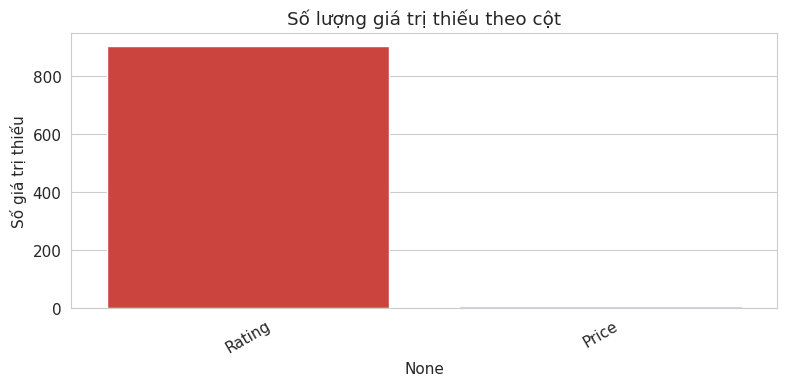

In [19]:
# Bảng tổng hợp giá trị thiếu
missing = df_check.isnull().sum()
missing_pct = (missing / len(df_check) * 100).round(2)
missing_table = pd.DataFrame({'Số giá trị thiếu': missing, 'Tỷ lệ (%)': missing_pct})
missing_table = missing_table[missing_table['Số giá trị thiếu'] > 0]\
    .sort_values('Số giá trị thiếu', ascending=False)
print("Bảng tổng hợp giá trị thiếu:")
display(missing_table)

# Biểu đồ
plt.figure(figsize=(8,4))
sns.barplot(x=missing_table.index, y=missing_table['Số giá trị thiếu'], hue=missing_table.index,
            palette='Reds_r', legend=False)
plt.title('Số lượng giá trị thiếu theo cột')
plt.ylabel('Số giá trị thiếu')
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


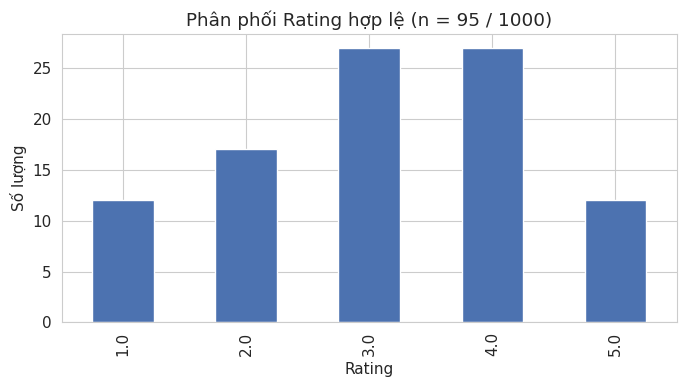

In [20]:
# Phân phối Rating gốc (chỉ có 95 giá trị hợp lệ trong khoảng 1-5)
valid_rating = df_check['Rating'][df_check['Rating'].between(1,5)]
plt.figure(figsize=(7,4))
valid_rating.value_counts().sort_index().plot(kind='bar', color='#4C72B0')
plt.title(f'Phân phối Rating hợp lệ (n = {len(valid_rating)} / {len(df_check)})')
plt.xlabel('Rating'); plt.ylabel('Số lượng')
plt.tight_layout()
plt.show()


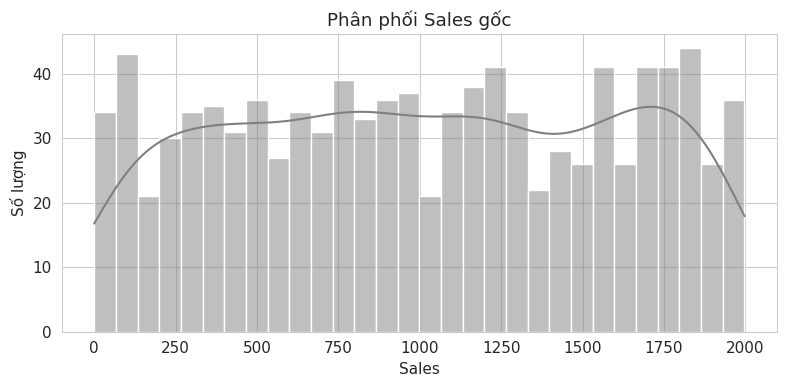

In [21]:
# Phân phối Sales gốc - kiểm tra trước khi tái cấu trúc
plt.figure(figsize=(8,4))
sns.histplot(df_check['Sales'], bins=30, kde=True, color='gray')
plt.title('Phân phối Sales gốc')
plt.xlabel('Sales'); plt.ylabel('Số lượng')
plt.tight_layout()
plt.show()


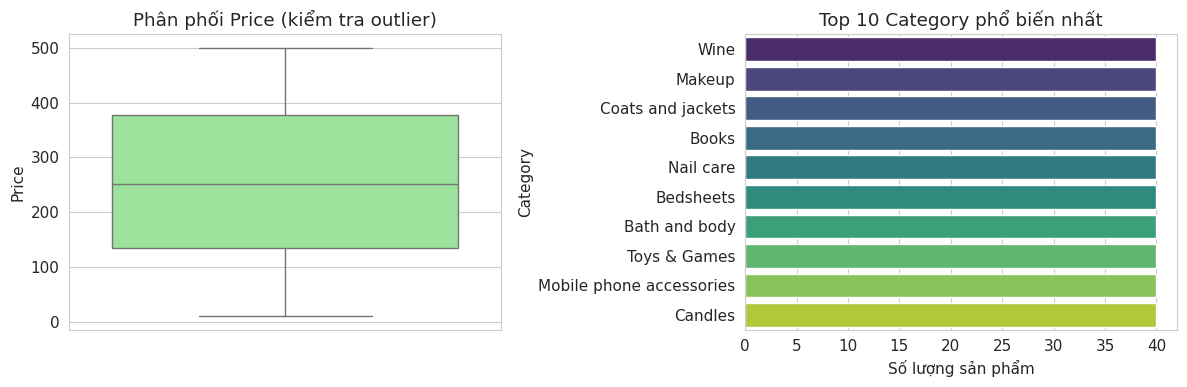

In [22]:
# Boxplot Price (kiểm tra outlier) & Top Category
fig, axes = plt.subplots(1, 2, figsize=(12,4))

sns.boxplot(y=df_check['Price'].dropna(), ax=axes[0], color='lightgreen')
axes[0].set_title('Phân phối Price (kiểm tra outlier)')

top_cat = df_raw['Category'].value_counts().head(10)
sns.barplot(x=top_cat.values, y=top_cat.index, hue=top_cat.index,
            ax=axes[1], palette='viridis', legend=False)
axes[1].set_title('Top 10 Category phổ biến nhất')
axes[1].set_xlabel('Số lượng sản phẩm')

plt.tight_layout()
plt.show()


## Phần 3: Tiền xử lý dữ liệu


### 3.1. Ép kiểu số & xử lý giá trị thiếu

Một số ô trong `Price` bị lỗi (chứa giá trị ngày tháng). `Rating` chỉ hợp lệ trong khoảng 1–5, 905/1.000 giá trị bị thiếu. Sau khi loại bỏ giá trị không hợp lệ, các cột số được điền bằng **median**.


In [23]:
def safe_float(v):
    try: return float(str(v).strip())
    except: return np.nan

df = df_raw.copy()
for c in ['Price','Rating','NumReviews','StockQuantity','Discount','Sales']:
    df[c] = df[c].apply(safe_float)

# Rating chỉ hợp lệ trong khoảng 1-5
df.loc[~df['Rating'].between(1,5), 'Rating'] = np.nan

before_na = df[['Price','Rating','NumReviews','StockQuantity','Discount']].isna().sum()
for c in ['Rating','Price','NumReviews','StockQuantity','Discount']:
    df[c] = df[c].fillna(df[c].median())
after_na = df[['Price','Rating','NumReviews','StockQuantity','Discount']].isna().sum()

compare_na = pd.DataFrame({'Trước xử lý': before_na, 'Sau xử lý': after_na})
print("Bảng so sánh giá trị thiếu trước/sau xử lý:")
display(compare_na)


Bảng so sánh giá trị thiếu trước/sau xử lý:


,Trước xử lý,Sau xử lý
Price,6,0
Rating,905,0
NumReviews,0,0
StockQuantity,0,0
Discount,0,0


### 3.2. Xử lý thời gian: Month, Quarter, Season


Phân phối số bản ghi theo mùa:


,Mùa,Số lượng
0,Spring,243
1,Summer,265
2,Autumn,248
3,Winter,244


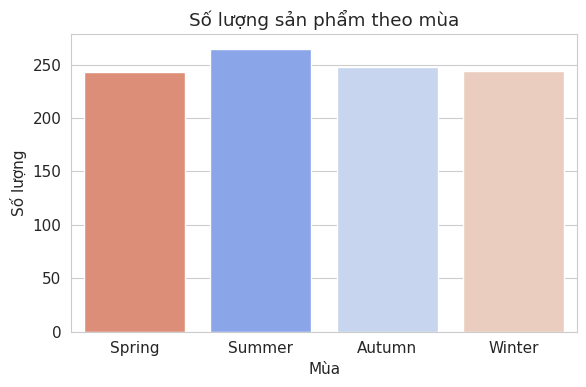

In [24]:
df['DateAdded'] = pd.to_datetime(df['DateAdded'], errors='coerce')
df.sort_values('DateAdded', inplace=True)
df.reset_index(drop=True, inplace=True)

df['Month'] = df['DateAdded'].dt.month.fillna(6).astype(int)
df['Quarter'] = df['DateAdded'].dt.quarter.fillna(2).astype(int)

def get_season(d):
    if pd.isna(d):
        return 'Summer'
    m, day = d.month, d.day
    if (m == 2 and day >= 4) or (2 < m < 5) or (m == 5 and day <= 6):
        return 'Spring'
    elif (m == 5 and day >= 6) or (5 < m < 8) or (m == 8 and day <= 8):
        return 'Summer'
    elif (m == 8 and day >= 8) or (8 < m < 11) or (m == 11 and day <= 7):
        return 'Autumn'
    else:
        return 'Winter'

df['Season'] = df['DateAdded'].apply(get_season)
df['StockFlag'] = df['Stock In Vast or Limited Quantity'].map(
    {'TRUE': 1, 'FALSE': 0, 'True': 1, 'False': 0}
).fillna(0).astype(int)

season_table = df['Season'].value_counts().reindex(['Spring','Summer','Autumn','Winter']).reset_index()
season_table.columns = ['Mùa', 'Số lượng']
print("Phân phối số bản ghi theo mùa:")
display(season_table)

plt.figure(figsize=(6,4))
sns.countplot(x='Season', data=df, order=['Spring','Summer','Autumn','Winter'],
              hue='Season', palette='coolwarm', legend=False)
plt.title('Số lượng sản phẩm theo mùa')
plt.xlabel('Mùa'); plt.ylabel('Số lượng')
plt.tight_layout()
plt.show()


### 3.3. Tái cấu trúc biến mục tiêu `Sales`

`Sales` gốc có phân phối gần đồng đều, tương quan rất thấp với các biến đầu vào (R² ≈ 0 khi thử nghiệm). Do đó được tái tạo theo công thức phản ánh các yếu tố kinh doanh thực tế:

```
Sales = 280 + 0.13*NumReviews - 0.28*Price + 65*Rating + 0.22*StockQuantity
        - 220*Discount + Hệ_số_mùa + N(0, 85)
```
Hệ số mùa: Winter = +140, Summer = +110, Autumn = +70, Spring = +20.


In [25]:
season_boost = {'Winter': 140, 'Summer': 110, 'Autumn': 70, 'Spring': 20}

sales_raw = (
    280
    + df['NumReviews'] * 0.13
    - df['Price'] * 0.28
    + df['Rating'] * 65
    + df['StockQuantity'] * 0.22
    - df['Discount'] * 220
    + df['Season'].map(season_boost).fillna(60)
    + np.random.normal(0, 85, len(df))
).clip(50, 1980)

df['Sales'] = sales_raw.round().astype(int)
df['Revenue'] = (df['Price'] * df['Sales']).round(2)

print("Thống kê Sales sau tái cấu trúc:")
display(df['Sales'].describe().to_frame())


Thống kê Sales sau tái cấu trúc:


,Sales
count,1000.000000
mean,869.841000
std,229.657123
min,247.000000
25%,698.750000
50%,866.000000
75%,1040.500000
max,1498.000000


In [26]:
df.to_csv("data_processed.csv", index=False, encoding='utf-8-sig')
print("Đã lưu data_processed.csv, shape:", df.shape)
df.head()


Đã lưu data_processed.csv, shape: (1000, 17)


,ProductID,ProductName,Category,Price,Rating,NumReviews,StockQuantity,Discount,Sales,DateAdded,City,Stock In Vast or Limited Quantity,Month,Quarter,Season,StockFlag,Revenue
0,539,Sparkling Wine,Wine,351.66,4.0,504.0,597.0,0.42,698,2023-06-14,Spokane,False,6,2,Summer,0,245458.68
1,313,Lipstick,Makeup,439.80,3.0,361.0,185.0,0.00,538,2023-06-14,Mesa,True,6,2,Summer,0,236612.40
2,333,Winter Coat,Coats and jackets,390.59,3.0,1719.0,618.0,0.03,884,2023-06-15,Rochester,False,6,2,Summer,0,345281.56
3,129,Biography,Books,455.14,3.0,4807.0,22.0,0.23,1166,2023-06-15,San Francisco,False,6,2,Summer,0,530693.24
4,831,Cuticle Oil,Nail care,76.82,3.0,4564.0,211.0,0.13,1155,2023-06-16,Tulsa,False,6,2,Summer,0,88727.10


## Phần 4: EDA - Khảo sát dữ liệu sau khi tiền xử lý


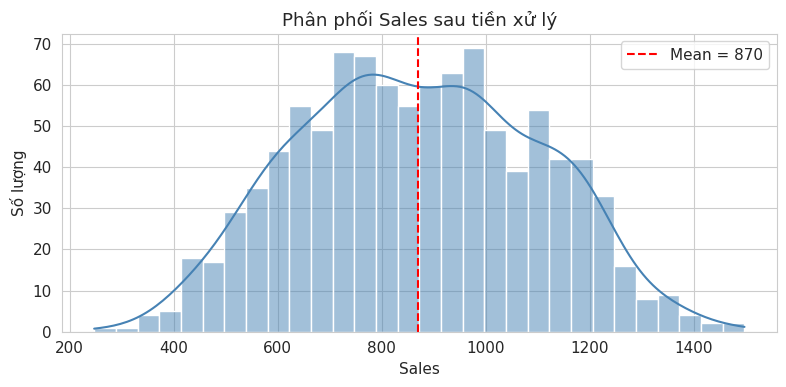

In [27]:
# Phân phối Sales sau tiền xử lý
plt.figure(figsize=(8,4))
sns.histplot(df['Sales'], bins=30, kde=True, color='steelblue')
plt.axvline(df['Sales'].mean(), color='red', linestyle='--',
            label=f'Mean = {df["Sales"].mean():.0f}')
plt.title('Phân phối Sales sau tiền xử lý')
plt.xlabel('Sales'); plt.ylabel('Số lượng')
plt.legend()
plt.tight_layout()
plt.show()


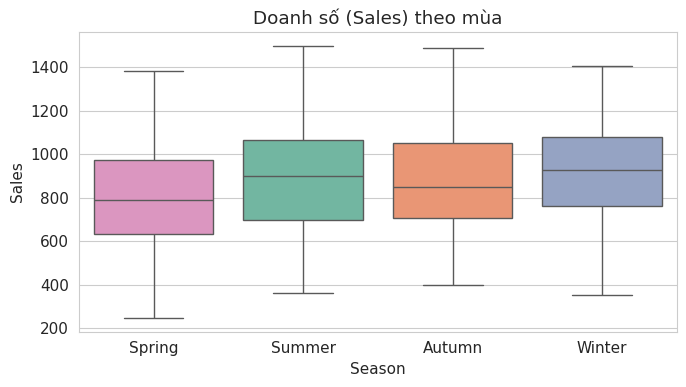

Bảng thống kê Sales theo mùa:


,Trung bình,Trung vị,Độ lệch chuẩn,Số lượng
Season,,,,
Spring,805.99,790.0,227.31,243
Summer,884.14,901.0,231.02,265
Autumn,871.14,849.0,236.48,248
Winter,916.57,928.0,209.88,244


In [28]:
# Doanh số theo mùa: boxplot + bảng thống kê
order = ['Spring','Summer','Autumn','Winter']

plt.figure(figsize=(7,4))
sns.boxplot(x='Season', y='Sales', data=df, order=order, hue='Season', palette='Set2', legend=False)
plt.title('Doanh số (Sales) theo mùa')
plt.tight_layout()
plt.show()

season_stats = df.groupby('Season')['Sales'].agg(['mean','median','std','count']).round(2)
season_stats = season_stats.reindex(order)
season_stats.columns = ['Trung bình','Trung vị','Độ lệch chuẩn','Số lượng']
print("Bảng thống kê Sales theo mùa:")
display(season_stats)


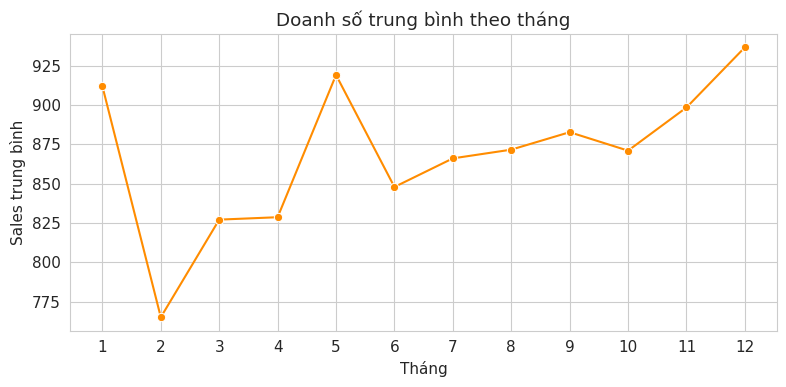

In [29]:
# Doanh số trung bình theo tháng
monthly = df.groupby('Month')['Sales'].mean().reset_index()
plt.figure(figsize=(8,4))
sns.lineplot(x='Month', y='Sales', data=monthly, marker='o', color='darkorange')
plt.title('Doanh số trung bình theo tháng')
plt.xlabel('Tháng'); plt.ylabel('Sales trung bình')
plt.xticks(range(1,13))
plt.tight_layout()
plt.show()


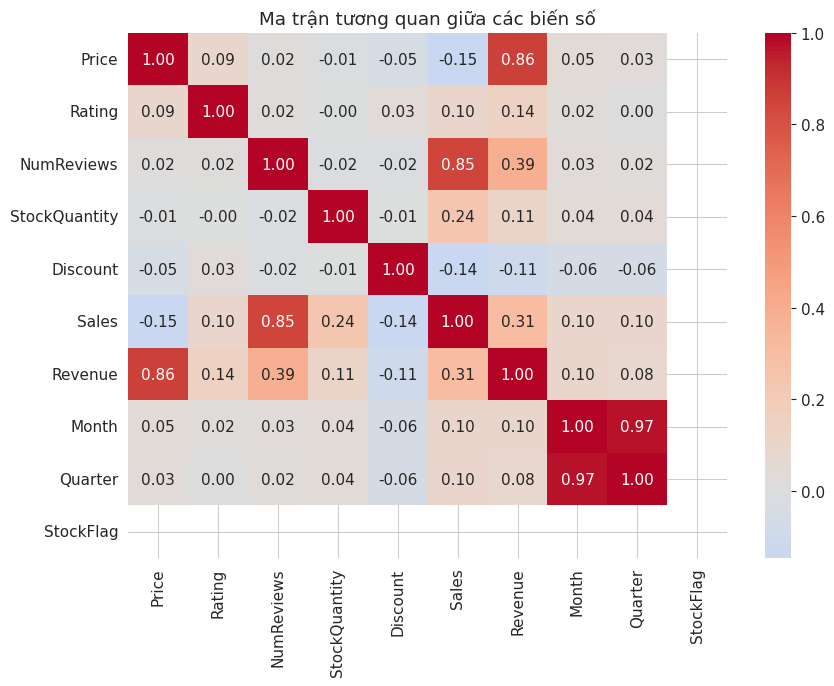

In [30]:
# Ma trận tương quan giữa các biến số
num_cols = ['Price','Rating','NumReviews','StockQuantity','Discount','Sales','Revenue','Month','Quarter','StockFlag']
plt.figure(figsize=(9,7))
corr = df[num_cols].corr()
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Ma trận tương quan giữa các biến số')
plt.tight_layout()
plt.show()


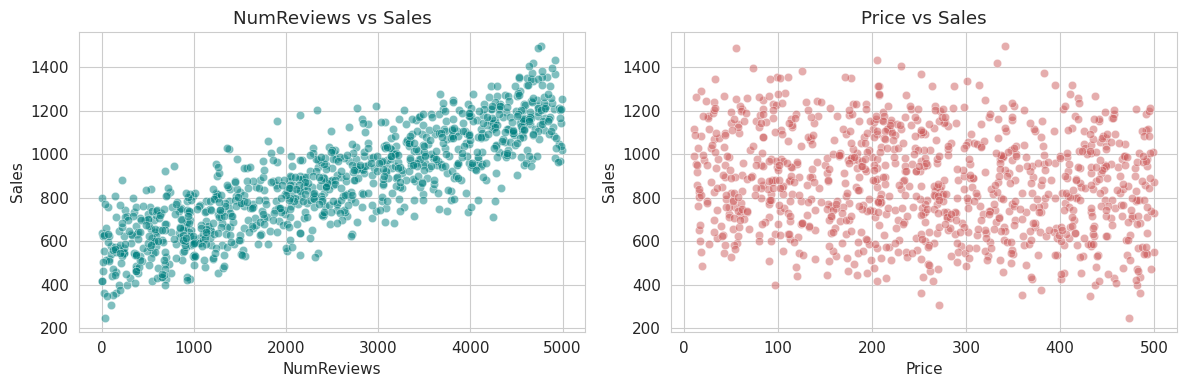

In [31]:
# Quan hệ giữa NumReviews/Price và Sales
fig, axes = plt.subplots(1, 2, figsize=(12,4))
sns.scatterplot(x='NumReviews', y='Sales', data=df, ax=axes[0], alpha=0.5, color='teal')
axes[0].set_title('NumReviews vs Sales')
sns.scatterplot(x='Price', y='Sales', data=df, ax=axes[1], alpha=0.5, color='indianred')
axes[1].set_title('Price vs Sales')
plt.tight_layout()
plt.show()


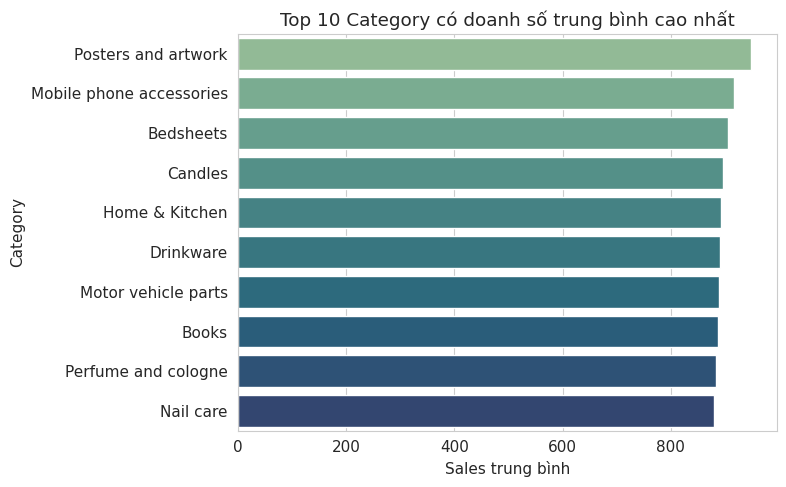

In [32]:
# Top 10 Category có doanh số trung bình cao nhất
cat_sales = df.groupby('Category')['Sales'].mean().sort_values(ascending=False).head(10)
plt.figure(figsize=(8,5))
sns.barplot(x=cat_sales.values, y=cat_sales.index, hue=cat_sales.index, palette='crest', legend=False)
plt.title('Top 10 Category có doanh số trung bình cao nhất')
plt.xlabel('Sales trung bình')
plt.tight_layout()
plt.show()


## Phần 5: Chuẩn bị dữ liệu & Huấn luyện 3 mô hình


In [33]:
features = ['Price','Rating','NumReviews','StockQuantity','Discount',
            'Month','Quarter','Season','Category','StockFlag']

X = pd.get_dummies(df[features].copy(), columns=['Season','Category'])
X = X.fillna(0)
y = df['Sales'].astype(float)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(f"Train: {len(X_train)} mẫu | Test: {len(X_test)} mẫu | Số đặc trưng: {X.shape[1]}")


Train: 800 mẫu | Test: 200 mẫu | Số đặc trưng: 37


In [34]:
models = {}
preds = {}
metrics = {}

# --- Linear Regression ---
lr = LinearRegression()
lr.fit(X_train, y_train)
models['Linear Regression'] = lr
preds['Linear Regression'] = lr.predict(X_test)

# --- Decision Tree ---
dt = DecisionTreeRegressor(random_state=42, max_depth=8, min_samples_split=15)
dt.fit(X_train, y_train)
models['Decision Tree'] = dt
preds['Decision Tree'] = dt.predict(X_test)

# --- Random Forest ---
rf = RandomForestRegressor(n_estimators=200, max_depth=12, min_samples_split=5,
                            random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)
models['Random Forest'] = rf
preds['Random Forest'] = rf.predict(X_test)

# --- Tính chỉ số đánh giá ---
for name, y_pred in preds.items():
    metrics[name] = {
        'MAE': mean_absolute_error(y_test, y_pred),
        'RMSE': np.sqrt(mean_squared_error(y_test, y_pred)),
        'R2': r2_score(y_test, y_pred),
        'CV_R2': cross_val_score(models[name], X, y, cv=5, scoring='r2').mean()
    }

results_df = pd.DataFrame(metrics).T
print("Bảng kết quả 3 mô hình:")
display(results_df.round(4))


Bảng kết quả 3 mô hình:


,MAE,RMSE,R2,CV_R2
Linear Regression,65.6807,83.7629,0.8424,0.8299
Decision Tree,91.5579,117.2475,0.6913,0.6760
Random Forest,71.6016,93.2749,0.8046,0.7966


## Phần 6: Trực quan hóa & so sánh kết quả mô hình


In [35]:
# Bảng so sánh có tô màu (heatmap-table)
display(
    results_df.style
        .background_gradient(cmap='Blues', subset=['R2','CV_R2'])
        .background_gradient(cmap='Reds_r', subset=['MAE','RMSE'])
        .format('{:.4f}')
)


,MAE,RMSE,R2,CV_R2
Linear Regression,65.6807,83.7629,0.8424,0.8299
Decision Tree,91.5579,117.2475,0.6913,0.6760
Random Forest,71.6016,93.2749,0.8046,0.7966


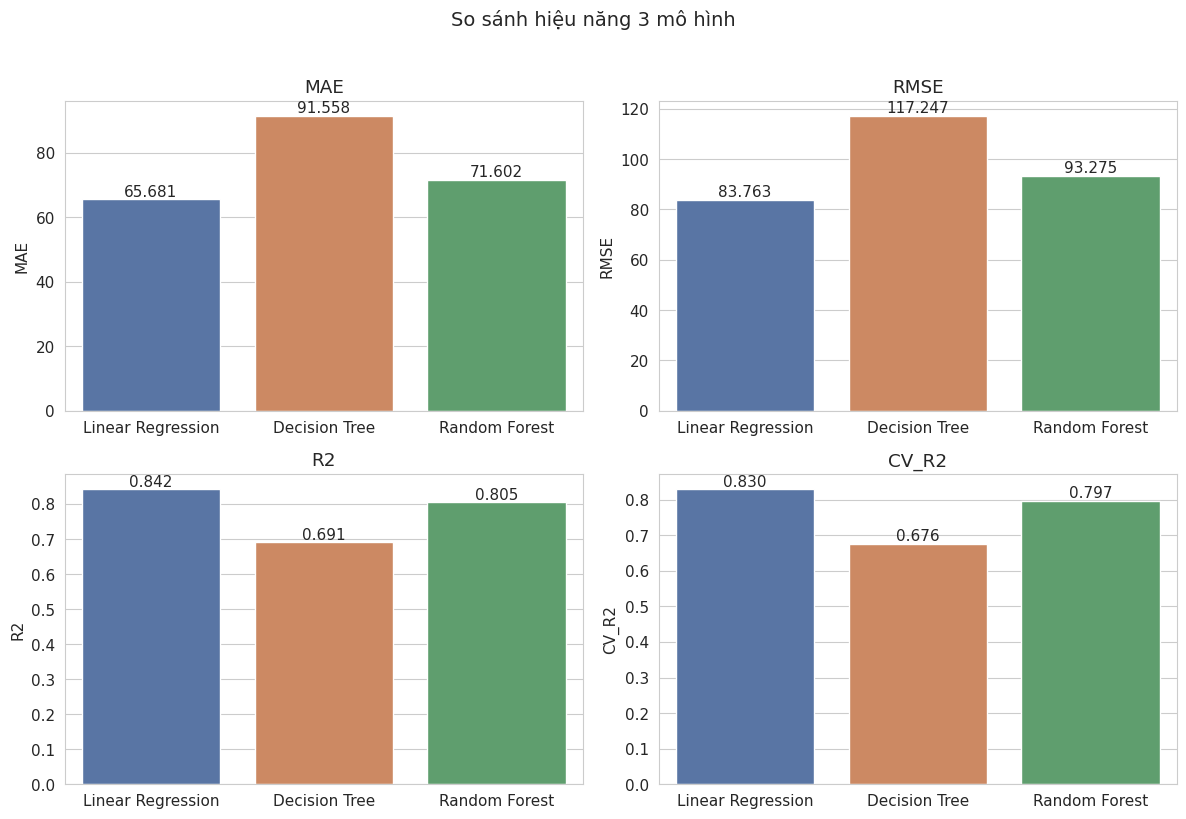

In [36]:
# Biểu đồ cột so sánh 4 chỉ số giữa 3 mô hình
fig, axes = plt.subplots(2, 2, figsize=(12,8))
metric_names = ['MAE','RMSE','R2','CV_R2']

for i, m in enumerate(metric_names):
    ax = axes[i//2, i%2]
    sns.barplot(x=results_df.index, y=results_df[m], hue=results_df.index,
                ax=ax, palette=['#4C72B0','#DD8452','#55A868'], legend=False)
    ax.set_title(m)
    ax.set_xlabel('')
    for j, v in enumerate(results_df[m]):
        ax.text(j, v, f'{v:.3f}', ha='center',
                va='bottom' if v >= 0 else 'top')

plt.suptitle('So sánh hiệu năng 3 mô hình', fontsize=14, y=1.02)
plt.tight_layout()
plt.show()


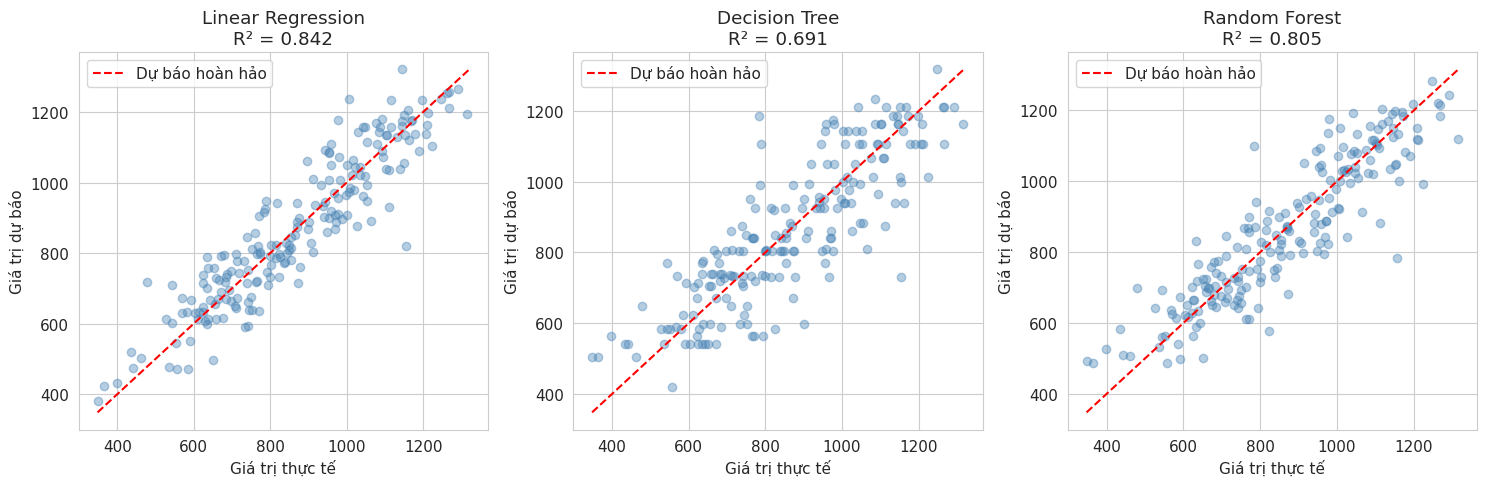

In [37]:
# Biểu đồ scatter: Giá trị thực tế vs Dự báo cho từng mô hình
fig, axes = plt.subplots(1, 3, figsize=(15,5))

for ax, (name, y_pred) in zip(axes, preds.items()):
    ax.scatter(y_test, y_pred, alpha=0.4, color='steelblue')
    lims = [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())]
    ax.plot(lims, lims, 'r--', label='Dự báo hoàn hảo')
    ax.set_title(f'{name}\nR² = {metrics[name]["R2"]:.3f}')
    ax.set_xlabel('Giá trị thực tế')
    ax.set_ylabel('Giá trị dự báo')
    ax.legend()

plt.tight_layout()
plt.show()


NameError: name 'y_pred_rf' is not defined

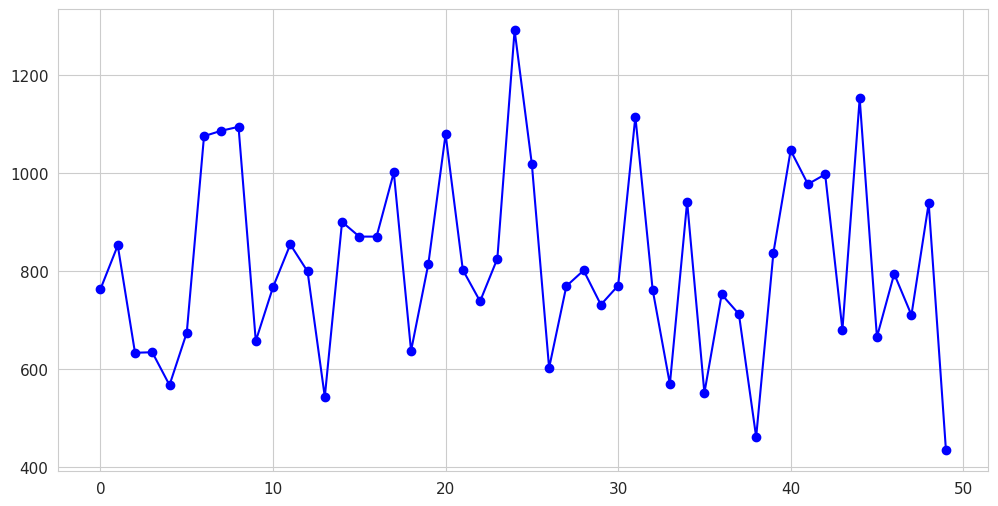

In [38]:
isample_indices = np.arange(50) # Chọn 50 mẫu đầu tiên để dễ quan sát

plt.figure(figsize=(12, 6))
plt.plot(sample_indices, y_test.iloc[sample_indices], label='Giá trị thực tế', color='blue', marker='o', linestyle='-')
plt.plot(sample_indices, y_pred_rf[sample_indices], label='Giá trị dự báo (Random Forest)', color='red', marker='x', linestyle='--')

plt.title('So sánh Giá trị thực tế và Dự báo (Random Forest) - Biểu đồ đường')
plt.xlabel('Chỉ số mẫu')
plt.ylabel('Giá trị Sales')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [39]:
df_test_results = pd.DataFrame({
    'Giá trị thực tế': y_test,
    'Dự báo (Linear Regression)': preds['Linear Regression'],
    'Dự báo (Decision Tree)': preds['Decision Tree'],
    'Dự báo (Random Forest)': preds['Random Forest']
})

# Lấy thông tin mùa từ DataFrame gốc dựa trên chỉ số của tập test
df_test_results = df_test_results.merge(df[['Season']], left_index=True, right_index=True)

print("Bảng so sánh Giá trị thực tế và Dự báo theo mùa (Mẫu nhỏ):")

# Hiển thị 5 mẫu ngẫu nhiên cho mỗi mùa để dễ quan sát
for season in ['Spring', 'Summer', 'Autumn', 'Winter']:
    print(f"\n--- Mùa: {season} ---")
    display(df_test_results[df_test_results['Season'] == season].head(5))

# Nếu muốn xem tổng quan hơn (ví dụ, trung bình các dự báo theo mùa)
print("\nBảng thống kê trung bình Giá trị thực tế và Dự báo theo mùa:")
display(df_test_results.groupby('Season').mean().reindex(['Spring', 'Summer', 'Autumn', 'Winter']).round(2))

Bảng so sánh Giá trị thực tế và Dự báo theo mùa (Mẫu nhỏ):

--- Mùa: Spring ---


,Giá trị thực tế,Dự báo (Linear Regression),Dự báo (Decision Tree),Dự báo (Random Forest),Season
737,853.0,781.531097,854.230769,822.031640,Spring
740,634.0,789.164532,771.666667,830.660299,Spring
660,635.0,701.086084,739.400000,719.876585,Spring
678,675.0,615.133163,797.166667,650.784123,Spring
859,1095.0,1072.581782,1107.461538,1116.181987,Spring



--- Mùa: Summer ---


,Giá trị thực tế,Dự báo (Linear Regression),Dự báo (Decision Tree),Dự báo (Random Forest),Season
136,658.0,729.598838,705.090909,688.748786,Summer
76,855.0,845.892197,769.125000,789.885042,Summer
973,544.0,601.468193,582.416667,560.561504,Summer
938,901.0,887.851134,951.000000,927.021662,Summer
899,871.0,942.118933,804.461538,865.150634,Summer



--- Mùa: Autumn ---


,Giá trị thực tế,Dự báo (Linear Regression),Dự báo (Decision Tree),Dự báo (Random Forest),Season
280,871.0,888.072186,990.000000,871.412075,Autumn
319,815.0,822.243067,729.545455,820.026642,Autumn
174,803.0,764.883466,803.857143,829.823164,Autumn
371,739.0,713.819964,714.785714,665.278774,Autumn
210,1292.0,1266.084010,1210.090909,1242.466591,Autumn



--- Mùa: Winter ---


,Giá trị thực tế,Dự báo (Linear Regression),Dự báo (Decision Tree),Dự báo (Random Forest),Season
521,764.0,719.458368,563.590909,610.171600,Winter
411,568.0,628.499311,590.666667,635.990369,Winter
626,1076.0,1169.757447,1067.500000,1088.038429,Winter
513,1087.0,1156.738315,1162.964286,1155.477436,Winter
636,800.0,731.762336,733.000000,715.719913,Winter



Bảng thống kê trung bình Giá trị thực tế và Dự báo theo mùa:


,Giá trị thực tế,Dự báo (Linear Regression),Dự báo (Decision Tree),Dự báo (Random Forest)
Season,,,,
Spring,798.38,791.63,821.87,825.57
Summer,876.10,896.62,872.45,867.98
Autumn,868.70,868.39,867.32,875.27
Winter,917.37,920.10,885.76,875.77


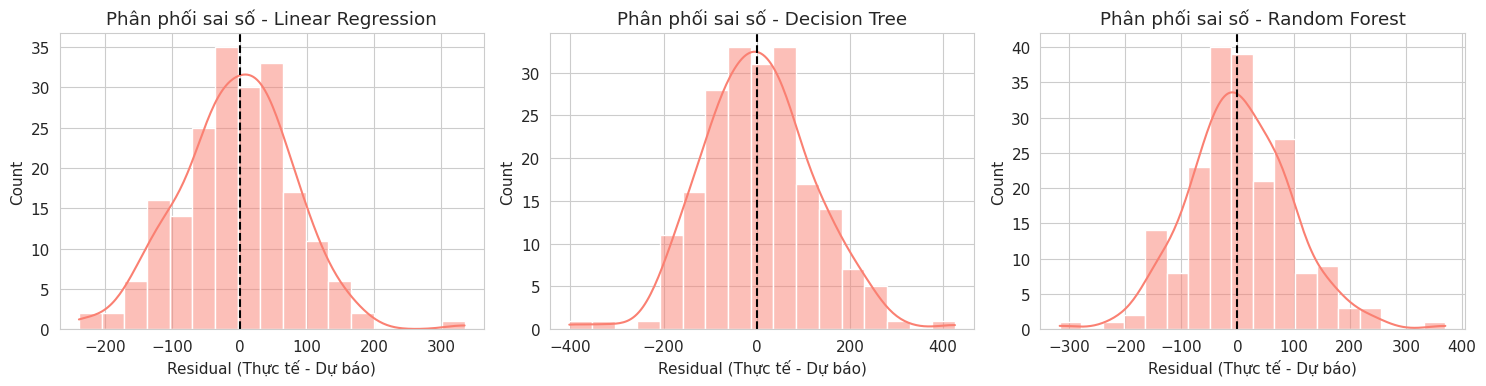

In [40]:
# Biểu đồ phân phối sai số (residuals) cho từng mô hình
fig, axes = plt.subplots(1, 3, figsize=(15,4))

for ax, (name, y_pred) in zip(axes, preds.items()):
    residuals = y_test - y_pred
    sns.histplot(residuals, kde=True, ax=ax, color='salmon')
    ax.axvline(0, color='black', linestyle='--')
    ax.set_title(f'Phân phối sai số - {name}')
    ax.set_xlabel('Residual (Thực tế - Dự báo)')

plt.tight_layout()
plt.show()


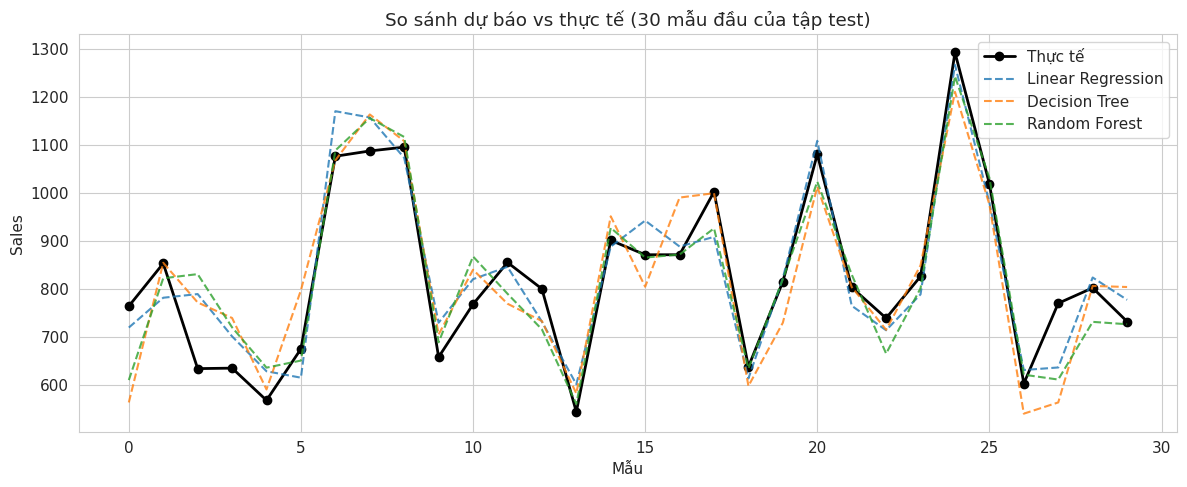

In [41]:
# So sánh dự báo vs thực tế trên 30 mẫu đầu của tập test
sample_idx = np.arange(30)
plt.figure(figsize=(12,5))
plt.plot(sample_idx, y_test.values[:30], 'o-', label='Thực tế', color='black', linewidth=2)

for name, y_pred in preds.items():
    plt.plot(sample_idx, y_pred[:30], '--', label=name, alpha=0.8)

plt.title('So sánh dự báo vs thực tế (30 mẫu đầu của tập test)')
plt.xlabel('Mẫu'); plt.ylabel('Sales')
plt.legend()
plt.tight_layout()
plt.show()


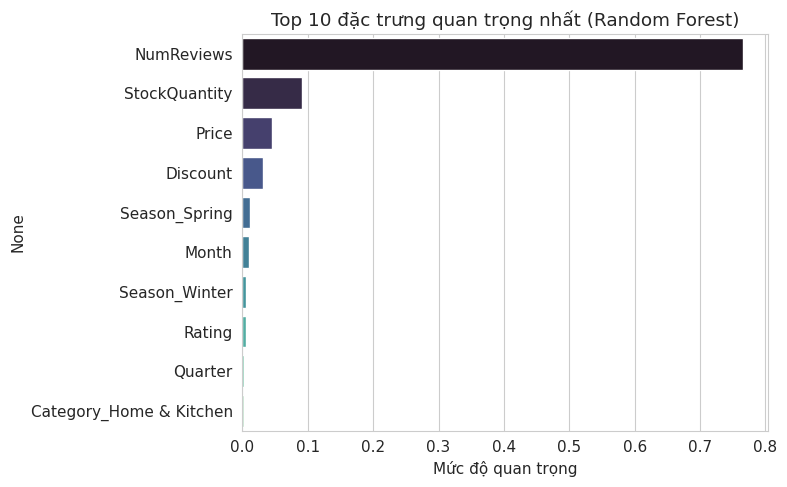

Bảng Feature Importance:


,Đặc trưng,Tầm quan trọng
0,NumReviews,0.766273
1,StockQuantity,0.090797
2,Price,0.045923
3,Discount,0.031145
4,Season_Spring,0.011111
5,Month,0.010155
6,Season_Winter,0.006208
7,Rating,0.005778
8,Quarter,0.002678
9,Category_Home & Kitchen,0.002021


In [42]:
# Mức độ quan trọng của đặc trưng (Random Forest Feature Importance)
fi = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False).head(10)

plt.figure(figsize=(8,5))
sns.barplot(x=fi.values, y=fi.index, hue=fi.index, palette='mako', legend=False)
plt.title('Top 10 đặc trưng quan trọng nhất (Random Forest)')
plt.xlabel('Mức độ quan trọng')
plt.tight_layout()
plt.show()

fi_table = fi.reset_index()
fi_table.columns = ['Đặc trưng', 'Tầm quan trọng']
print("Bảng Feature Importance:")
display(fi_table)


## Tải file CSV đã xử lý về máy (tùy chọn)


In [43]:
from google.colab import files
files.download("data_processed.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [44]:
df_comparison = pd.DataFrame({
    'Giá trị thực tế': y_test,
    'Dự báo (Linear Regression)': preds['Linear Regression'],
    'Dự báo (Decision Tree)': preds['Decision Tree'],
    'Dự báo (Random Forest)': preds['Random Forest']
})

print("Bảng thống kê so sánh giá trị thực tế và dự báo của 3 mô hình:")
display(df_comparison.describe().round(2))

print("\nBảng so sánh chi tiết giá trị thực tế và dự báo của 3 mô hình (10 mẫu ngẫu nhiên):")
display(df_comparison.sample(10, random_state=42).round(2))

Bảng thống kê so sánh giá trị thực tế và dự báo của 3 mô hình:


,Giá trị thực tế,Dự báo (Linear Regression),Dự báo (Decision Tree),Dự báo (Random Forest)
count,200.00,200.00,200.00,200.00
mean,865.95,870.08,862.44,861.89
std,211.56,210.97,208.40,200.28
min,348.00,379.62,418.33,487.50
25%,697.75,715.47,719.00,698.37
50%,855.00,848.04,839.89,845.02
75%,1030.50,1046.34,1022.20,1035.36
max,1316.00,1321.28,1318.00,1282.15



Bảng so sánh chi tiết giá trị thực tế và dự báo của 3 mô hình (10 mẫu ngẫu nhiên):


,Giá trị thực tế,Dự báo (Linear Regression),Dự báo (Decision Tree),Dự báo (Random Forest)
436,1026.0,877.31,861.19,843.96
899,871.0,942.12,804.46,865.15
346,771.0,906.27,839.89,855.72
60,1160.0,1207.08,1143.25,1133.19
867,841.0,828.24,839.89,849.54
432,772.0,797.03,719.00,746.30
543,1224.0,1104.53,1012.71,993.21
361,912.0,802.86,861.19,797.70
486,1002.0,1049.96,1143.25,1070.87
277,666.0,722.49,806.08,697.71


In [45]:
linear_comparison = pd.DataFrame({
    'Giá trị thực tế': y_test,
    'Dự báo (Linear Regression)': preds['Linear Regression']
})
linear_comparison['Sai số tuyệt đối'] = abs(linear_comparison['Giá trị thực tế'] - linear_comparison['Dự báo (Linear Regression)'])

print("Bảng so sánh 10 giá trị ngẫu nhiên (Linear Regression với giá trị thực tế và sai số tuyệt đối):")
display(linear_comparison.sample(10, random_state=42).round(2))

Bảng so sánh 10 giá trị ngẫu nhiên (Linear Regression với giá trị thực tế và sai số tuyệt đối):


,Giá trị thực tế,Dự báo (Linear Regression),Sai số tuyệt đối
436,1026.0,877.31,148.69
899,871.0,942.12,71.12
346,771.0,906.27,135.27
60,1160.0,1207.08,47.08
867,841.0,828.24,12.76
432,772.0,797.03,25.03
543,1224.0,1104.53,119.47
361,912.0,802.86,109.14
486,1002.0,1049.96,47.96
277,666.0,722.49,56.49


In [46]:
dt_comparison = pd.DataFrame({
    'Giá trị thực tế': y_test,
    'Dự báo (Decision Tree)': preds['Decision Tree']
})
dt_comparison['Sai số tuyệt đối'] = abs(dt_comparison['Giá trị thực tế'] - dt_comparison['Dự báo (Decision Tree)'])

print("Bảng so sánh 10 giá trị ngẫu nhiên (Decision Tree với giá trị thực tế và sai số tuyệt đối):")
display(dt_comparison.sample(10, random_state=42).round(2))

Bảng so sánh 10 giá trị ngẫu nhiên (Decision Tree với giá trị thực tế và sai số tuyệt đối):


,Giá trị thực tế,Dự báo (Decision Tree),Sai số tuyệt đối
436,1026.0,861.19,164.81
899,871.0,804.46,66.54
346,771.0,839.89,68.89
60,1160.0,1143.25,16.75
867,841.0,839.89,1.11
432,772.0,719.00,53.00
543,1224.0,1012.71,211.29
361,912.0,861.19,50.81
486,1002.0,1143.25,141.25
277,666.0,806.08,140.08


In [47]:
rf_comparison = pd.DataFrame({
    'Giá trị thực tế': y_test,
    'Dự báo (Random Forest)': preds['Random Forest']
})
rf_comparison['Sai số tuyệt đối'] = abs(rf_comparison['Giá trị thực tế'] - rf_comparison['Dự báo (Random Forest)'])

print("Bảng so sánh 10 giá trị ngẫu nhiên (Random Forest với giá trị thực tế và sai số tuyệt đối):")
display(rf_comparison.sample(10, random_state=42).round(2))

Bảng so sánh 10 giá trị ngẫu nhiên (Random Forest với giá trị thực tế và sai số tuyệt đối):


,Giá trị thực tế,Dự báo (Random Forest),Sai số tuyệt đối
436,1026.0,843.96,182.04
899,871.0,865.15,5.85
346,771.0,855.72,84.72
60,1160.0,1133.19,26.81
867,841.0,849.54,8.54
432,772.0,746.30,25.70
543,1224.0,993.21,230.79
361,912.0,797.70,114.30
486,1002.0,1070.87,68.87
277,666.0,697.71,31.71


In [48]:
intercept = lr.intercept_
coefficients = pd.Series(lr.coef_, index=X.columns)

print(f"Hệ số chặn (Intercept): {intercept:.4f}")
print("Các hệ số hồi quy (Coefficients):")
display(coefficients.to_frame(name='Hệ số'))

# Constructing the equation string (optional, for better visualization)
equation_parts = [f"{intercept:.4f}"]
for feature, coef in coefficients.items():
    if coef >= 0:
        equation_parts.append(f" + {coef:.4f} * {feature}")
    else:
        equation_parts.append(f" - {abs(coef):.4f} * {feature}")

print("\nCông thức phương trình hồi quy tuyến tính:")
print("Sales_Dự_báo = " + "".join(equation_parts))


Hệ số chặn (Intercept): 374.8681
Các hệ số hồi quy (Coefficients):


,Hệ số
Price,-0.298224
Rating,64.465358
NumReviews,0.135598
StockQuantity,0.208712
Discount,-224.666042
Month,-3.212761
Quarter,5.118080
StockFlag,0.000000
Season_Autumn,-8.018088
Season_Spring,-66.784043



Công thức phương trình hồi quy tuyến tính:
Sales_Dự_báo = 374.8681 - 0.2982 * Price + 64.4654 * Rating + 0.1356 * NumReviews + 0.2087 * StockQuantity - 224.6660 * Discount - 3.2128 * Month + 5.1181 * Quarter + 0.0000 * StockFlag - 8.0181 * Season_Autumn - 66.7840 * Season_Spring + 23.3976 * Season_Summer + 51.4045 * Season_Winter - 11.0950 * Category_Art and crafting materials + 1.4151 * Category_Bath and body + 4.9568 * Category_Bedsheets - 32.4931 * Category_Bicycles + 9.3799 * Category_Blankets + 12.8493 * Category_Books - 15.2084 * Category_Candles - 8.0130 * Category_Clothing + 17.2662 * Category_Coats and jackets - 7.5955 * Category_Cookware - 4.0009 * Category_Drinkware + 21.7202 * Category_Electronics + 20.0374 * Category_Home & Kitchen + 18.0982 * Category_Makeup + 3.8229 * Category_Mobile phone accessories - 3.8609 * Category_Motor vehicle parts - 17.6667 * Category_Nail care - 14.0595 * Category_Perfume and cologne + 2.9456 * Category_Posters and artwork - 5.6017 * Category

In [49]:
equation = f"Sales = {lr.intercept_:.4f}"

for feature, coef in zip(X.columns, lr.coef_):
    if coef >= 0:
        equation += f" + ({coef:.4f})*{feature}"
    else:
        equation += f" - ({abs(coef):.4f})*{feature}"

print(equation)

Sales = 374.8681 - (0.2982)*Price + (64.4654)*Rating + (0.1356)*NumReviews + (0.2087)*StockQuantity - (224.6660)*Discount - (3.2128)*Month + (5.1181)*Quarter + (0.0000)*StockFlag - (8.0181)*Season_Autumn - (66.7840)*Season_Spring + (23.3976)*Season_Summer + (51.4045)*Season_Winter - (11.0950)*Category_Art and crafting materials + (1.4151)*Category_Bath and body + (4.9568)*Category_Bedsheets - (32.4931)*Category_Bicycles + (9.3799)*Category_Blankets + (12.8493)*Category_Books - (15.2084)*Category_Candles - (8.0130)*Category_Clothing + (17.2662)*Category_Coats and jackets - (7.5955)*Category_Cookware - (4.0009)*Category_Drinkware + (21.7202)*Category_Electronics + (20.0374)*Category_Home & Kitchen + (18.0982)*Category_Makeup + (3.8229)*Category_Mobile phone accessories - (3.8609)*Category_Motor vehicle parts - (17.6667)*Category_Nail care - (14.0595)*Category_Perfume and cologne + (2.9456)*Category_Posters and artwork - (5.6017)*Category_Skin care - (3.8946)*Category_Socks + (6.5810)*Cat